# Cost training: Gamma regression for LLM inference costs

**Location:** Save this notebook in `2.1_Cost_Training/` at the repository root, alongside `2_Router_Training/`.

**Purpose:** Tune Gamma regularization by training-only grouped cross-validation; compare Gamma regression against Ridge regression and a training-mean baseline for predicting RouterBench inference costs for 11 LLMs. Evaluate both character TF-IDF and E5-plus-four-features using the same prepared splits as the team.

This notebook **predicts costs only**; it does not train the five-class score classifiers, perform routing, or evaluate on the test split.

For each model $m$, fit a positive conditional mean:

$$
\mathbb{E}[c_{im}\mid x_i] = \bar c_m\exp\!\left(\alpha_m + \boldsymbol{\beta}_m^T\phi(x_i)\right).
$$

Targets are normalized by their training mean, then predictions are converted back to dollar costs. `GammaRegressor` minimizes Gamma deviance with L2 coefficient regularization. The Gamma hyperparameters in this notebook are illustrative and **not cross-validated**.

**Prerequisite:** Complete the TF-IDF and E5 preparation notebooks, producing `1_data_preparation/data/processed/`.


**Output organization:** detailed timestamped artifacts are saved under `experiment_outputs/gamma_cost_regression/calibration_runs/`, while compact shareable CSV/PNG summaries are saved under `results/`. Existing older runs are not moved or overwritten.

Suggested root `.gitignore` entry: `2.1_Cost_Training/experiment_outputs/` (do not ignore `2.1_Cost_Training/results/`).


## 1. Configuration and dependencies

Install dependencies in the same Python environment used for data preparation:

```bash
python -m pip install numpy pandas scipy scikit-learn joblib ipykernel matplotlib
```

Store this notebook in `2.1_Cost_Training/` and run from anywhere **inside the project tree**. The code locates your processed input files regardless of whether VS Code starts Jupyter at the repository root or in the notebook folder. Detailed experiment outputs are stored under `2.1_Cost_Training/experiment_outputs/gamma_cost_regression/calibration_runs/`. A small shareable summary table and plot are written to `2.1_Cost_Training/results/`. The code locates either supported processed-data layout. Start with `RUN_MODE="smoke"` to verify compatibility, then set `"full"` and restart/run all cells. The smoke run is **not** a scientifically meaningful comparison.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import os
import warnings

import joblib
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from scipy.sparse import load_npz
from sklearn.linear_model import GammaRegressor, Ridge
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error

RUN_MODE = "full"  # set "full" for final CV and calibration evaluation
SEED = 42
DATA_PREPARATION_DIR = None  # optional path to folder containing data/
OUTPUT_BASE_OVERRIDE = None
SMOKE_LIMITS = {"train": 512, "calibration": 128, "validation": 256}

# Tune Gamma alpha using grouped cross-validation on TRAINING only.
GAMMA_ALPHA_GRID = [0.001, 0.01, 0.1, 1.0]
CV_FOLDS = 3
RIDGE_ALPHA = {"tfidf": 10.0, "e5_388": 1.0}  # teammate's cost baseline
GAMMA_MAX_ITER = 600

assert RUN_MODE in ("smoke", "full")
print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.9.1


## 2. Locate and load exactly the same prepared datasets

The TF-IDF feature matrix saved by Step 1 contains a final length column. Like your teammate's modeling notebook, we **remove** that length column for the pure-TF-IDF comparison. E5 uses all 388 dimensions.

In [2]:
def resolve_preparation_dir(override=None):
    requested = override or os.environ.get("ERDOS_DATA_DIR")
    if requested is not None:
        candidates = [Path(requested).expanduser().resolve()]
    else:
        working_dir = Path.cwd().resolve()
        candidates = [candidate for parent in (working_dir, *working_dir.parents)
                      for candidate in (parent, parent / "1_data_preparation")]
    required = (
        Path("data/processed/char_tfidf_50k/preprocessing.joblib"),
        Path("data/processed/multilingual_e5_small_chunk480/embedding_metadata.json"),
    )
    for candidate in dict.fromkeys(candidates):
        if all((candidate / rel).is_file() for rel in required):
            return candidate
    raise FileNotFoundError("Could not find processed files. Set DATA_PREPARATION_DIR to folder containing data/.")

preparation_dir = resolve_preparation_dir(DATA_PREPARATION_DIR)
table_dir = preparation_dir / "data/processed/char_tfidf_50k"
e5_dir = preparation_dir / "data/processed/multilingual_e5_small_chunk480"
project_dir = preparation_dir.parent if preparation_dir.name == "1_data_preparation" else preparation_dir
output_base = (Path(OUTPUT_BASE_OVERRIDE).expanduser().resolve() if OUTPUT_BASE_OVERRIDE
               else project_dir / "2.1_Cost_Training/experiment_outputs/gamma_cost_regression/calibration_runs")
run_dir = output_base / f"{RUN_MODE}_seed{SEED}_{datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')}"
run_dir.mkdir(parents=True, exist_ok=False)
shareable_results_dir = project_dir / "2.1_Cost_Training/results"
shareable_results_dir.mkdir(parents=True, exist_ok=True)
print("Prepared data:", preparation_dir)
print("Outputs:", run_dir)
print("Shareable summaries:", shareable_results_dir)

Prepared data: /Users/haotanhan/Documents/Career/DataScience/ErdosBootCamp/Project/fall-2026-right-for-less/fall-2026-right-for-less/1_data_preparation
Outputs: /Users/haotanhan/Documents/Career/DataScience/ErdosBootCamp/Project/fall-2026-right-for-less/fall-2026-right-for-less/2.1_Cost_Training/experiment_outputs/gamma_cost_regression/calibration_runs/full_seed42_20261019T214403_393020Z
Shareable summaries: /Users/haotanhan/Documents/Career/DataScience/ErdosBootCamp/Project/fall-2026-right-for-less/fall-2026-right-for-less/2.1_Cost_Training/results


In [3]:
preprocessing = joblib.load(table_dir / "preprocessing.joblib")
model_names = list(preprocessing["model_names"])
n_tfidf = len(preprocessing["tfidf_vectorizer"].vocabulary_)
SPLITS = ("train", "calibration", "validation")
feature_names = {"tfidf": "Pure character TF-IDF", "e5_388": "E5 + four features"}

tables = {}
features = {name: {} for name in feature_names}
for split_index, split in enumerate(SPLITS):
    full = {key: pd.read_pickle(table_dir / f"{split}_{key}.pkl")
            for key in ("questions", "scores", "costs")}
    q, s, c = [full[key] for key in ("questions", "scores", "costs")]
    assert q.index.is_unique and q.index.equals(s.index) and q.index.equals(c.index)
    assert s.columns.tolist() == c.columns.tolist() == model_names
    assert np.isfinite(c.to_numpy(dtype=float)).all() and c.gt(0).all().all()
    tfidf = load_npz(table_dir / f"X_{split}.npz")[:, :n_tfidf].astype(np.float32).tocsr()
    e5 = np.load(e5_dir / f"X_{split}_e5_full_features.npy", allow_pickle=False)
    assert tfidf.shape == (len(q), n_tfidf)
    assert e5.shape == (len(q), 388)
    if RUN_MODE == "smoke":
        rng = np.random.default_rng(SEED + split_index)
        ix = np.sort(rng.choice(len(q), size=min(len(q), SMOKE_LIMITS[split]), replace=False))
    else:
        ix = np.arange(len(q))
    tables[split] = {key: frame.iloc[ix].copy() for key, frame in full.items()}
    features["tfidf"][split] = tfidf[ix].copy()
    features["e5_388"][split] = e5[ix].copy()
    tables[split]["questions"][["sample_id"]].to_csv(run_dir / f"{split}_rows.csv")

# Verify that the same original questions do not occur in different splits.
all_q = pd.concat([tables[split]["questions"].assign(_split=split) for split in SPLITS])
assert all_q.groupby("question_text")["_split"].nunique().le(1).all()
assert all_q.groupby("question_group")["_split"].nunique().le(1).all()

display(pd.DataFrame({"n_questions": {s: len(tables[s]["questions"]) for s in SPLITS}}))
print("Candidate LLMs:", len(model_names))
print("TF-IDF columns:", n_tfidf, " E5 columns: 388")

,n_questions
train,21900
calibration,3648
validation,3649


Candidate LLMs: 11
TF-IDF columns: 50000  E5 columns: 388


## 3. Tune Gamma penalty by grouped training-only cross-validation, then refit

The project README specifies hyperparameter selection by cross-validation *within the training partition*. We use three-fold `GroupKFold` with `question_group`, so no question group is split across training and held-out folds. For each candidate `alpha`, fit one Gamma GLM per LLM on each training fold and calculate **the mean of 11 per-LLM WAPEs** on the held-out fold; aggregate the held-out absolute errors and costs across all folds before computing WAPE. Choose **one alpha per feature representation**. Fold-specific cost means are calculated only from the fitting portion of each fold, preventing preprocessing leakage. The untouched calibration split is used only after alpha is chosen and each Gamma model is refitted on the entire training split. Validation scores/costs remain unused.

The complete run makes `number_of_alphas × CV_FOLDS × 11 × 2` Gamma fits for CV, plus 22 final fits. Smoke mode checks code flow only; it is **not** for selecting a research-quality alpha. Group CV can take significantly longer than the earlier fixed-alpha notebook.


In [4]:
y_train = tables["train"]["costs"].to_numpy(dtype=np.float64)
cost_means = y_train.mean(axis=0)
assert np.all(cost_means > 0)
y_normalized = y_train / cost_means[None, :]

groups = tables["train"]["questions"]["question_group"].to_numpy()
assert len(np.unique(groups)) >= CV_FOLDS
folds = list(GroupKFold(n_splits=CV_FOLDS).split(np.arange(len(groups)), groups=groups))

cv_rows = []
selected_gamma_alpha = {}
for feature in feature_names:
    X = features[feature]["train"]
    for alpha in GAMMA_ALPHA_GRID:
        total_abs_error = np.zeros(len(model_names), dtype=np.float64)
        total_actual_cost = np.zeros(len(model_names), dtype=np.float64)
        max_iterations = 0
        warning_count = 0
        for fold_no, (fit_idx, hold_idx) in enumerate(folds, start=1):
            # Normalize each LLM by the mean of *this fold's fitting data* only.
            fold_cost_means = y_train[fit_idx].mean(axis=0)
            assert np.all(fold_cost_means > 0)
            X_fit, X_hold = X[fit_idx], X[hold_idx]
            actual = y_train[hold_idx]
            for j in range(len(model_names)):
                glm = GammaRegressor(alpha=alpha, max_iter=GAMMA_MAX_ITER, tol=1e-6)
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always", ConvergenceWarning)
                    glm.fit(X_fit, y_train[fit_idx, j] / fold_cost_means[j])
                warning_count += sum(issubclass(w.category, ConvergenceWarning) for w in caught)
                max_iterations = max(max_iterations, int(glm.n_iter_))
                estimated = glm.predict(X_hold) * fold_cost_means[j]
                total_abs_error[j] += np.abs(estimated - actual[:, j]).sum()
                total_actual_cost[j] += actual[:, j].sum()
        wape_by_llm = 100 * total_abs_error / total_actual_cost
        cv_rows.append({"Features": feature, "Alpha": alpha,
                        "CV WAPE (%)": float(wape_by_llm.mean()),
                        "Max iterations": max_iterations,
                        "Convergence warnings": warning_count})
        print(f"CV {feature} alpha={alpha:g}: WAPE={wape_by_llm.mean():.2f}% "
              f"(warnings={warning_count})")
    feature_rows = [r for r in cv_rows if r["Features"] == feature]
    best = min(feature_rows, key=lambda r: (r["CV WAPE (%)"], r["Alpha"]))
    selected_gamma_alpha[feature] = float(best["Alpha"])
    print(f"Selected {feature} alpha={best['Alpha']:g} using training-only CV")

cv_metrics = pd.DataFrame(cv_rows)
display(cv_metrics.sort_values(["Features", "CV WAPE (%)"]))
cv_metrics.to_csv(run_dir / "training_group_cv_gamma_alpha.csv", index=False)

predictions = {}  # (method, feature, split) -> pandas DataFrame of predicted USD costs
models = {}
fit_rows = []
for feature in feature_names:
    X_train = features[feature]["train"]
    gamma_models = []
    for j, model_name in enumerate(model_names):
        glm = GammaRegressor(alpha=selected_gamma_alpha[feature],
                             max_iter=GAMMA_MAX_ITER, tol=1e-6)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            glm.fit(X_train, y_normalized[:, j])
        converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
        if not converged:
            warnings.warn(f"Gamma solver warning for {feature}, {model_name}; inspect convergence.")
        gamma_models.append(glm)
        fit_rows.append({"Features": feature, "LLM": model_name,
                         "Gamma_alpha": selected_gamma_alpha[feature],
                         "Iterations": int(glm.n_iter_),
                         "Converged_no_warning": converged})
        print(f"Final Gamma {feature}: {j+1}/{len(model_names)}")
    ridge = Ridge(alpha=RIDGE_ALPHA[feature], solver="lsqr", tol=1e-3,
                  max_iter=1000).fit(X_train, y_normalized)
    models[feature] = {"Gamma": gamma_models, "Ridge": ridge}
    for split in ("calibration", "validation"):
        X = features[feature][split]
        gamma_usd = np.column_stack([g.predict(X) for g in gamma_models]) * cost_means[None, :]
        ridge_usd = np.maximum(ridge.predict(X), 1e-6) * cost_means[None, :]
        mean_usd = np.broadcast_to(cost_means, gamma_usd.shape).copy()
        for name, values in [("Gamma", gamma_usd), ("Ridge", ridge_usd),
                             ("Training mean", mean_usd)]:
            assert values.shape == (len(tables[split]["questions"]), len(model_names))
            assert np.isfinite(values).all() and (values > 0).all()
            predictions[(name, feature, split)] = pd.DataFrame(
                values, index=tables[split]["costs"].index, columns=model_names
            )

display(pd.DataFrame(fit_rows).groupby("Features")[["Iterations", "Converged_no_warning"]].agg(
    {"Iterations": "max", "Converged_no_warning": "all"}))


CV tfidf alpha=0.001: WAPE=15.07% (warnings=0)
CV tfidf alpha=0.01: WAPE=22.01% (warnings=0)
CV tfidf alpha=0.1: WAPE=41.63% (warnings=0)
CV tfidf alpha=1: WAPE=57.56% (warnings=0)
Selected tfidf alpha=0.001 using training-only CV
CV e5_388 alpha=0.001: WAPE=13.47% (warnings=0)
CV e5_388 alpha=0.01: WAPE=16.02% (warnings=0)
CV e5_388 alpha=0.1: WAPE=18.03% (warnings=0)
CV e5_388 alpha=1: WAPE=28.32% (warnings=0)
Selected e5_388 alpha=0.001 using training-only CV


,Features,Alpha,CV WAPE (%),Max iterations,Convergence warnings
4,e5_388,0.001,13.474461,114,0
5,e5_388,0.010,16.018511,44,0
6,e5_388,0.100,18.028621,22,0
7,e5_388,1.000,28.315439,13,0
0,tfidf,0.001,15.069256,55,0
1,tfidf,0.010,22.012910,23,0
2,tfidf,0.100,41.631843,14,0
3,tfidf,1.000,57.557534,9,0


Final Gamma tfidf: 1/11
Final Gamma tfidf: 2/11
Final Gamma tfidf: 3/11
Final Gamma tfidf: 4/11
Final Gamma tfidf: 5/11
Final Gamma tfidf: 6/11
Final Gamma tfidf: 7/11
Final Gamma tfidf: 8/11
Final Gamma tfidf: 9/11
Final Gamma tfidf: 10/11
Final Gamma tfidf: 11/11
Final Gamma e5_388: 1/11
Final Gamma e5_388: 2/11
Final Gamma e5_388: 3/11
Final Gamma e5_388: 4/11
Final Gamma e5_388: 5/11
Final Gamma e5_388: 6/11
Final Gamma e5_388: 7/11
Final Gamma e5_388: 8/11
Final Gamma e5_388: 9/11
Final Gamma e5_388: 10/11
Final Gamma e5_388: 11/11


,Iterations,Converged_no_warning
Features,,
e5_388,107,True
tfidf,53,True


## 4. Compare cost prediction on calibration

As in the teammate's README, compute each metric separately for each LLM and **average the 11 values equally**. WAPE is the average of per-model ratios (not pooled WAPE). All costs remain in USD.

In [5]:
def cost_metrics(y, pred):
    y = np.asarray(y, dtype=float)
    pred = np.asarray(pred, dtype=float)
    assert y.shape == pred.shape
    mse_each = np.mean((pred-y)**2, axis=0)
    mae_each = np.mean(np.abs(pred-y), axis=0)
    wape_each = np.sum(np.abs(pred-y), axis=0) / np.sum(np.abs(y), axis=0)
    return {"Cost MSE (USD²)": float(mse_each.mean()),
            "Cost MAE (USD)": float(mae_each.mean()),
            "Cost WAPE (%)": float(100*wape_each.mean())}

rows = []
for (method, feature, split), frame in predictions.items():
    if split != "calibration":
        continue
    rows.append({"Method": method, "Features": feature,
                 **cost_metrics(tables[split]["costs"].to_numpy(), frame.to_numpy())})
metrics = pd.DataFrame(rows).sort_values(["Cost WAPE (%)", "Cost MAE (USD)"])
display(metrics.style.format({"Cost MSE (USD²)": "{:.4e}",
                              "Cost MAE (USD)": "${:.8f}", "Cost WAPE (%)": "{:.2f}"}))
metrics.to_csv(run_dir / "calibration_cost_metrics.csv", index=False)

,Method,Features,Cost MSE (USD²),Cost MAE (USD),Cost WAPE (%)
4,Ridge,e5_388,3.4486e-07,$0.00015718,14.37
0,Gamma,tfidf,4.5774e-07,$0.00014571,15.27
3,Gamma,e5_388,1.0920e-06,$0.00014277,15.62
1,Ridge,tfidf,4.2117e-07,$0.00016771,17.24
2,Training mean,tfidf,1.8725e-06,$0.00058923,61.46
5,Training mean,e5_388,1.8725e-06,$0.00058923,61.46


### Per-LLM diagnostic table

Average metrics can hide poor prediction for particular models. Check individual LLMs, especially those with unusually large or small training costs.

In [6]:
detailed = []
y_calibration = tables["calibration"]["costs"].to_numpy(dtype=float)
for (method, feature, split), frame in predictions.items():
    if split != "calibration":
        continue
    errors = np.abs(frame.to_numpy() - y_calibration)
    for j, model in enumerate(model_names):
        detailed.append({"Method": method, "Features": feature, "LLM": model,
                         "MAE (USD)": errors[:, j].mean(),
                         "WAPE (%)": 100 * errors[:, j].sum() / y_calibration[:, j].sum()})
per_llm = pd.DataFrame(detailed)
display(per_llm.sort_values("WAPE (%)").head(20))
per_llm.to_csv(run_dir / "calibration_cost_metrics_per_llm.csv", index=False)

,Method,Features,LLM,MAE (USD),WAPE (%)
50,Ridge,e5_388,meta/code-llama-instruct-34b-chat,0.000017,9.989867
51,Ridge,e5_388,meta/llama-2-70b-chat,0.000021,10.098211
53,Ridge,e5_388,mistralai/mixtral-8x7b-chat,0.000014,10.229557
44,Ridge,e5_388,WizardLM/WizardLM-13B-V1.2,0.000009,11.612946
7,Gamma,tfidf,meta/llama-2-70b-chat,0.000025,12.548807
9,Gamma,tfidf,mistralai/mixtral-8x7b-chat,0.000017,12.797434
6,Gamma,tfidf,meta/code-llama-instruct-34b-chat,0.000022,12.869970
52,Ridge,e5_388,mistralai/mistral-7b-chat,0.000006,13.205301
40,Gamma,e5_388,meta/llama-2-70b-chat,0.000027,13.209996
0,Gamma,tfidf,WizardLM/WizardLM-13B-V1.2,0.000010,13.460030


## 5. Export small, GitHub-friendly calibration summaries

This cell saves **only calibration** aggregate metrics and a figure to `2.1_Cost_Training/results/`. It never reads validation labels. The shareable files are overwritten on each run; only export results from `RUN_MODE="full"` for team reporting. Detailed timestamped files remain in `experiment_outputs/`.
Training-only Gamma CV diagnostics are also saved to the timestamped experiment folder.


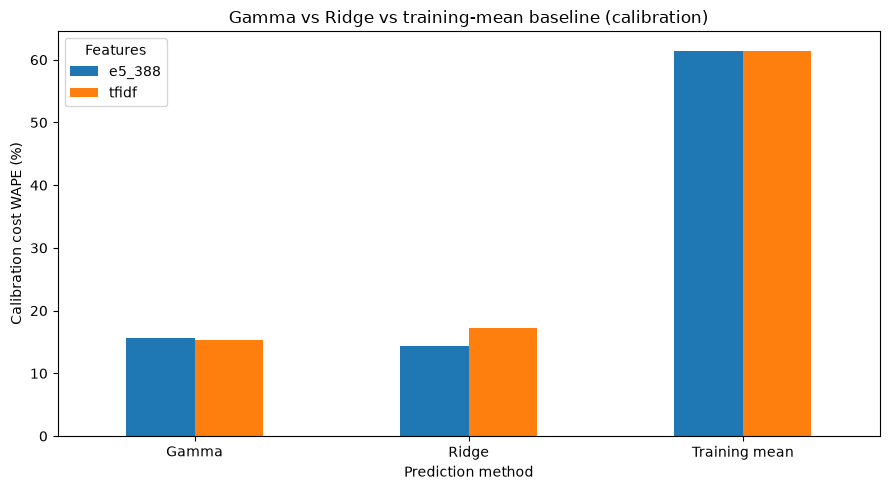

Shareable metrics: /Users/haotanhan/Documents/Career/DataScience/ErdosBootCamp/Project/fall-2026-right-for-less/fall-2026-right-for-less/2.1_Cost_Training/results/gamma_vs_ridge_calibration_metrics.csv
Shareable plot: /Users/haotanhan/Documents/Career/DataScience/ErdosBootCamp/Project/fall-2026-right-for-less/fall-2026-right-for-less/2.1_Cost_Training/results/gamma_vs_ridge_calibration_wape.png


In [7]:
if RUN_MODE == "full":
    import matplotlib.pyplot as plt

    summary_path = shareable_results_dir / "gamma_vs_ridge_calibration_metrics.csv"
    metrics.to_csv(summary_path, index=False)
    cv_metrics.to_csv(shareable_results_dir / "gamma_training_cv_alpha.csv", index=False)

    plot_data = metrics.pivot(index="Method", columns="Features", values="Cost WAPE (%)")
    ax = plot_data.plot.bar(figsize=(9, 5), rot=0)
    ax.set_ylabel("Calibration cost WAPE (%)")
    ax.set_xlabel("Prediction method")
    ax.set_title("Gamma vs Ridge vs training-mean baseline (calibration)")
    ax.legend(title="Features")
    plt.tight_layout()
    figure_path = shareable_results_dir / "gamma_vs_ridge_calibration_wape.png"
    plt.savefig(figure_path, dpi=160)
    plt.show()
    print("Shareable metrics:", summary_path)
    print("Shareable plot:", figure_path)
else:
    print("Smoke mode: no shareable results exported. Use RUN_MODE='full' for final summaries.")

## 6. Save models and predictions for later routing experiments

The calibration split is **not used to fit these cost models**. Calibration metrics and predictions, plus validation predictions without evaluation, are saved, along with model names, cost normalization values, and configuration. Another teammate can load these files for the routing stage without rerunning Gamma fitting.

**Git note:** The resulting model/prediction files can be large. Add `2.1_Cost_Training/experiment_outputs/` to the repository `.gitignore` before staging notebook work if you do not intend to version these outputs.

The `results/` CSV and PNG are intended for sharing. If you commit the notebook, clear unnecessary large cell outputs before staging.


In [8]:
for (method, feature, split), frame in predictions.items():
    key = method.lower().replace(" ", "_")
    frame.to_pickle(run_dir / f"cost_predictions_{key}_{feature}_{split}.pkl")

joblib.dump(models, run_dir / "cost_models_gamma_and_ridge.joblib")
metadata = {
    "run_mode": RUN_MODE, "seed": SEED, "model_names": model_names,
    "features": feature_names, "gamma_alpha": selected_gamma_alpha, "gamma_alpha_grid": GAMMA_ALPHA_GRID,
    "gamma_cv_folds": CV_FOLDS, "gamma_cv_selection_metric": "mean per-LLM out-of-fold WAPE",
    "ridge_alpha": RIDGE_ALPHA, "cost_means": cost_means.tolist(),
    "prepared_data_directory": str(preparation_dir),
    "sklearn_version": sklearn.__version__,
    "metrics": "Unweighted mean across 11 per-LLM metrics; WAPE expressed as a percentage",
    "test_evaluated": False,
    "metrics_evaluation_split": "calibration",
    "routing_validation_labels_used": False,
    "gamma_alpha_tuned": True, "gamma_alpha_tuned_on": "train (grouped CV)",
}
(run_dir / "experiment_manifest.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved results to:", run_dir)

Saved results to: /Users/haotanhan/Documents/Career/DataScience/ErdosBootCamp/Project/fall-2026-right-for-less/fall-2026-right-for-less/2.1_Cost_Training/experiment_outputs/gamma_cost_regression/calibration_runs/full_seed42_20261019T214403_393020Z


## 7. Experimental protocol and reporting

- **Training:** grouped three-fold CV selects `GammaRegressor.alpha` separately for pure TF-IDF and E5+features, then all Gamma coefficients are refitted on all training questions. Ridge is an unchanged fixed-hyperparameter comparison (its `alpha` has *not* been cross-validated in this notebook).
- **Calibration:** compare fitted Gamma, Ridge, and mean-cost predictions; do not use calibration to choose Gamma alpha.
- **Validation:** only save predictions, not score/cost performance metrics; reserve labels for routing-policy selection.
- **Test:** never accessed in this notebook.
- **Files:** detailed experiment artifacts and CV table under `2.1_Cost_Training/experiment_outputs/gamma_cost_regression/calibration_runs/<timestamp>/`; GitHub-friendly calibration summary and plot in `2.1_Cost_Training/results/`.

To report a fair fully tuned Gamma-versus-Ridge comparison, Ridge regularization should also be selected using training-only cross-validation. The current Ridge rows reproduce the teammate's fixed configuration.
